In [11]:
from langgraph.graph import StateGraph, START, END
# from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Annotated
from dotenv import load_dotenv
import operator
import os


# load_dotenv()
# api_key = os.getenv("GEMINI_API_KEY")

# llm = ChatGoogleGenerativeAI(
#     model = "gemini-3.5-flash-lite",
#     api_key = api_key
# )

In [12]:
class InfoState(TypedDict):
    arr : list[int]
    even : int
    odd : int
    prime_no : list[int]
    summary : str
    

In [13]:
def even_count(state: InfoState):
    arr = state['arr']
    count = 0
    for n in arr:
        if n%2 == 0:
            count +=1
    return {'even' : count}

In [14]:
def odd_count(state: InfoState):
    arr = state['arr']
    count = 0
    for n in arr:
        if n%2 != 0:
            count +=1
    return {'odd' : count}

In [15]:
def prime_count(state: InfoState):
    arr = state['arr']
    primes = []
    for n in arr:
        is_prime = True
        for i in range(2,n):
            if n%i == 0:
                is_prime = False
        if is_prime:
            primes.append(n)
    return {'prime_no' : primes}

In [16]:
def summary(state: InfoState):
    arr = state['arr']
    evens = state['even']
    odds = state['odd']
    primes = state['prime_no']

    smry = f"Your {arr} has \n\t Even : {evens} \n\t Odd : {odds} \n\t Prime Numbers : {primes}"

    return {'summary' : smry}

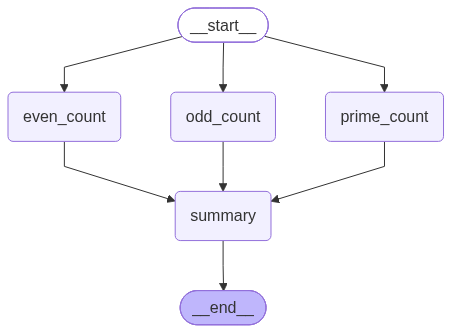

In [17]:
graph = StateGraph(InfoState)

graph.add_node("even_count",even_count)
graph.add_node("odd_count", odd_count)
graph.add_node("prime_count", prime_count)
graph.add_node("summary", summary)

graph.add_edge(START, "even_count")
graph.add_edge(START, "odd_count")
graph.add_edge(START, "prime_count")

graph.add_edge("even_count", "summary")
graph.add_edge("odd_count", "summary")
graph.add_edge("prime_count", "summary")

graph.add_edge("summary", END)

workflow = graph.compile()
workflow

In [21]:
initial_state = {'arr' : [3,4,5,6,7,8,9,10,11]}
final_state = workflow.invoke(initial_state)

print(final_state['summary'])

Your [3, 4, 5, 6, 7, 8, 9, 10, 11] has 
	 Even : 4 
	 Odd : 5 
	 Prime Numbers : [3, 5, 7, 11]
